In [1]:
%% MIT 18.03 Lecture 39: Dangers of Linearization, Limit Cycles & Lorenz Chaos
% Description: Capstone simulation for MIT 18.03 using Control System Toolbox & ODE solvers:
%              1) Borderline Linearization Failure: x' = -y - y^2, y' = x + y^2 (Linear Center vs Nonlinear Spiral).
%              2) Zero-Jacobian 6-Ray Portrait: x' = 4xy, y' = x^2 - y^2 (2nd-order dominated).
%              3) van der Pol Limit Cycle: x'' + a*(x^2 - 1)*x' + x = 0 (Global periodic attractor).
%              4) 3D Lorenz Strange Attractor: x' = a*(y - x), y' = r*x - y - x*z, z' = x*y - b*z.
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, pole).
%
% % MBD Concept Mapping: Demonstrates breakdown of Jacobian linearization on stability boundaries
% %                      (Re(lambda) = 0), self-sustained limit-cycle oscillations in nonlinear plants,
% %                      and 3D chaotic strange attractors around unstable equilibrium wings.


clear; clc; close all;


%% =========================================================================
%% Part 1: Borderline Linearization Failure (Lecture Section [2] Example 1)
%% =========================================================================
% Nonlinear system: x' = -y - y^2,  y' = x + y^2
% Jacobian at (0,0): J = [0, -1; 1, 0] -> tr = 0, det = 1 -> Linear Center (lambda = +/- i)
J_border = [0, -1;
            1,  0];
sys_border_lin = ss(J_border, zeros(2,1), eye(2), zeros(2,1));
poles_border   = pole(sys_border_lin);


fprintf('=== MIT 18.03 Lecture 39 Capstone Diagnostics ===\n');

=== MIT 18.03 Lecture 39 Capstone Diagnostics ===

In [2]:
fprintf('1) Borderline System: x'' = -y - y^2, y'' = x + y^2\n');

1) Borderline System: x' = -y - y^2, y' = x + y^2

In [3]:
fprintf('   Linearized Poles at (0,0) : %+.2f %+.2fi (Predicts Neutrally Stable Center)\n', ...
        real(poles_border(1)), imag(poles_border(1)));

   Linearized Poles at (0,0) : +0.00 +1.00i (Predicts Neutrally Stable Center)

In [4]:
fprintf('   Actual Nonlinear Behavior : Sub-exponentially decaying Stable Spiral!\n\n');

   Actual Nonlinear Behavior : Sub-exponentially decaying Stable Spiral!

In [5]:


t_b = linspace(0, 60, 2000);
u0_b = [0.45; 0.0];
[u_border_lin, ~] = initial(sys_border_lin, u0_b, t_b);
opts = odeset('RelTol', 1e-9, 'AbsTol', 1e-11);
[~, u_border_nl] = ode45(@(t, U) [-U(2) - U(2)^2; U(1) + U(2)^2], t_b, u0_b, opts);


%% =========================================================================
%% Part 2: Van der Pol Oscillator Limit Cycle (Lecture Section [3])
%% =========================================================================
% Equation: x'' + a*(x^2 - 1)*x' + x = 0  <--->  x' = y, y' = -x - a*(x^2 - 1)*y
a_vdp = 1.5;
% Linearization at origin (0,0): J_vdp = [0, 1; -1, +a] -> tr = +a > 0, det = 1 (Unstable Source!)
J_vdp_origin = [0, 1; -1, a_vdp];
sys_vdp_lin  = ss(J_vdp_origin, zeros(2,1), eye(2), zeros(2,1));
poles_vdp    = pole(sys_vdp_lin);


fprintf('2) van der Pol Oscillator (a = %.2f): x'''' + a*(x^2 - 1)*x'' + x = 0\n', a_vdp);

2) van der Pol Oscillator (a = 1.50): x'' + a*(x^2 - 1)*x' + x = 0

In [6]:
fprintf('   Origin Jacobian Poles     : %+.4f %+.4fi (Unstable Anti-Damped Repeller)\n', ...
        real(poles_vdp(1)), imag(poles_vdp(1)));

   Origin Jacobian Poles     : +0.7500 +0.6614i (Unstable Anti-Damped Repeller)

In [7]:
fprintf('   Global Phase Portrait     : Unique Stable Limit Cycle Attractor!\n\n');

   Global Phase Portrait     : Unique Stable Limit Cycle Attractor!

In [8]:


t_vdp = linspace(0, 30, 1500);
ode_vdp = @(t, U) [U(2); -U(1) - a_vdp * (U(1)^2 - 1) * U(2)];
[~, u_vdp_in]  = ode45(ode_vdp, t_vdp, [0.1; 0.0], opts); % Spirals OUT from inside
[~, u_vdp_out] = ode45(ode_vdp, t_vdp, [3.0; 3.0], opts); % Spirals IN from outside


%% =========================================================================
%% Part 3: 3D Lorenz Strange Attractor (Lecture Section [4])
%% =========================================================================
% Lorenz Equations (Lecture notation: a=10, b=8/3, r=28):
% x' = -a*x + a*y,  y' = -x*z + r*x - y,  z' = x*y - b*z
a_lor = 10.0;
b_lor = 8.0 / 3.0;
r_lor = 28.0;


% Nonzero equilibria exist for r > 1: C+/- = ( +/- sqrt(b*(r-1)), +/- sqrt(b*(r-1)), r - 1 )
x_eq_lor = sqrt(b_lor * (r_lor - 1));
z_eq_lor = r_lor - 1;


% 3x3 Jacobian at the positive wing equilibrium C+ = (x_eq, x_eq, z_eq)
J_lorenz_wing = [-a_lor,            a_lor,   0;
                  r_lor - z_eq_lor, -1,     -x_eq_lor;
                  x_eq_lor,         x_eq_lor, -b_lor];
sys_lorenz_wing = ss(J_lorenz_wing, zeros(3,1), eye(3), zeros(3,1));
poles_lorenz    = pole(sys_lorenz_wing);


fprintf('3) 3D Lorenz System (a = %.1f, b = %.3f, r = %.1f):\n', a_lor, b_lor, r_lor);

3) 3D Lorenz System (a = 10.0, b = 2.667, r = 28.0):

In [9]:
fprintf('   Wing Equilibria C+/-      : (%.2f, %.2f, %.2f) and (%.2f, %.2f, %.2f)\n', ...
        x_eq_lor, x_eq_lor, z_eq_lor, -x_eq_lor, -x_eq_lor, z_eq_lor);

   Wing Equilibria C+/-      : (8.49, 8.49, 27.00) and (-8.49, -8.49, 27.00)

In [10]:
fprintf('   3D Wing Jacobian Poles    : %.4f,  %+.4f %+.4fi (Unstable Spiral-Saddle!)\n', ...
        poles_lorenz(1), real(poles_lorenz(2)), abs(imag(poles_lorenz(2))));

   3D Wing Jacobian Poles    : -13.8546,  +0.0940 +10.1945i (Unstable Spiral-Saddle!)

In [11]:
fprintf('=================================================\n');


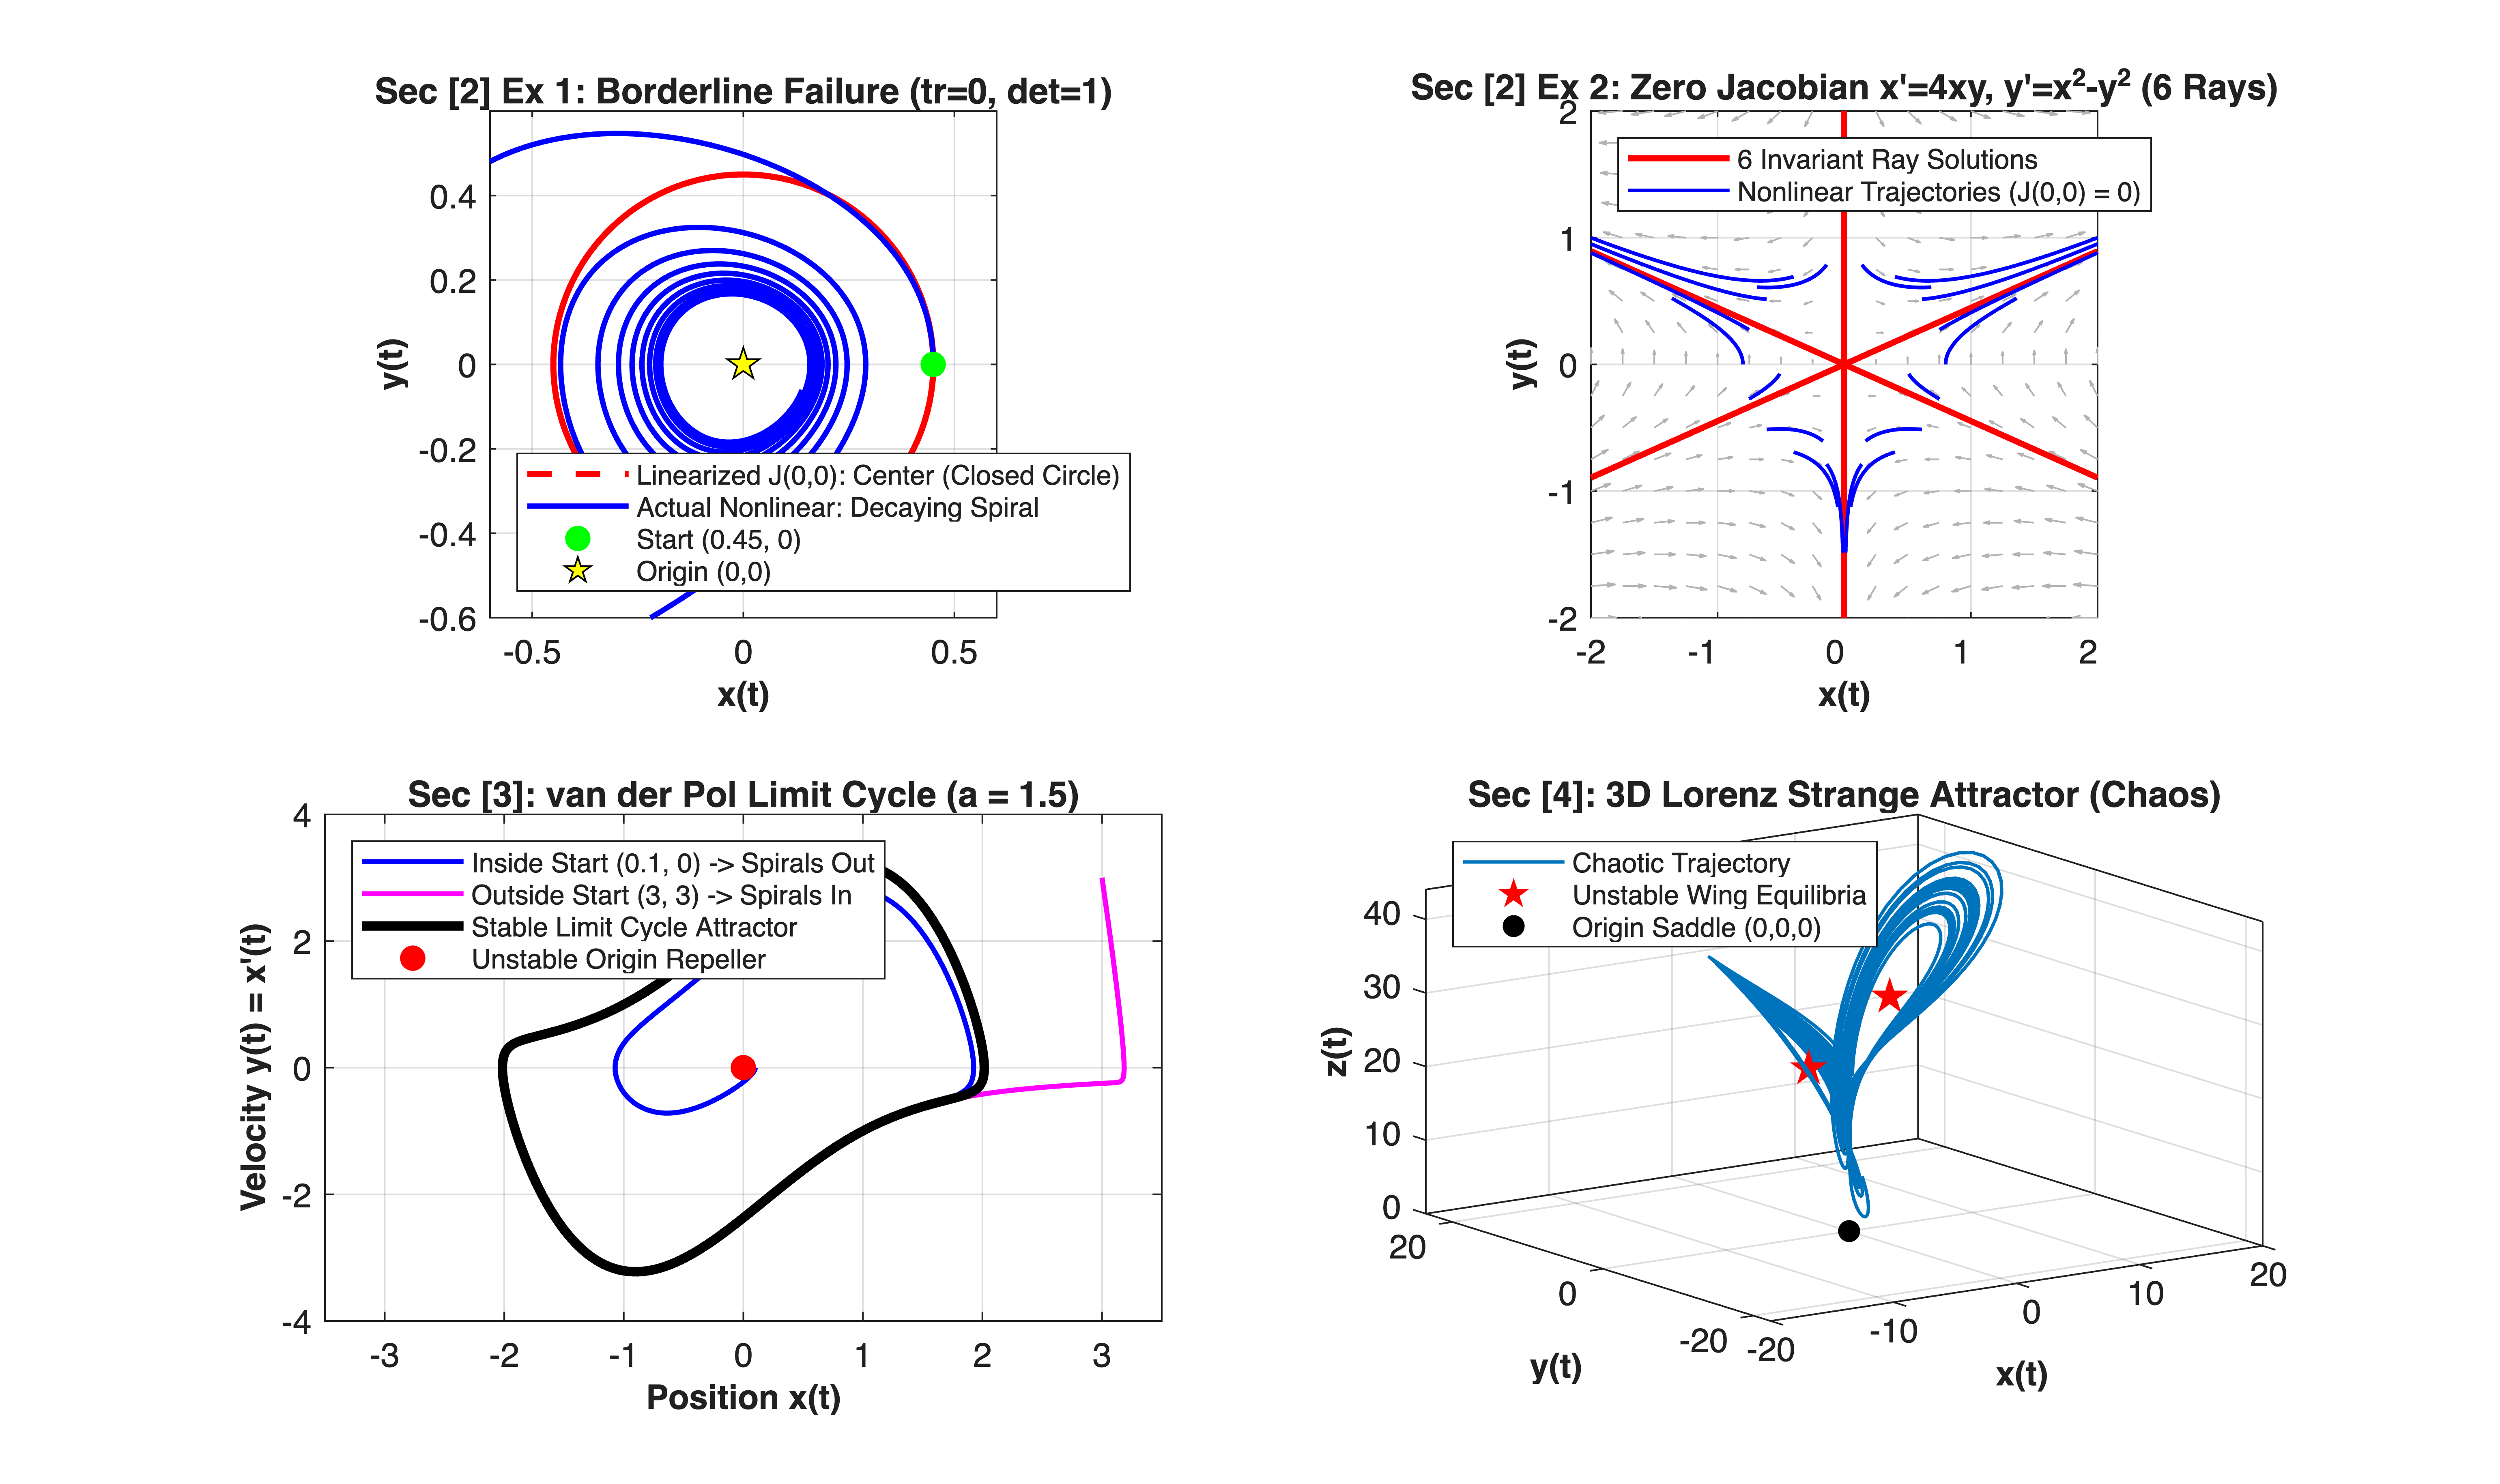

In [12]:


t_lor = linspace(0, 35, 4000);
ode_lorenz = @(t, U) [-a_lor*U(1) + a_lor*U(2);
                      -U(1)*U(3) + r_lor*U(1) - U(2);
                       U(1)*U(2) - b_lor*U(3)];
[~, U_lorenz] = ode45(ode_lorenz, t_lor, [1.0; 1.0; 20.0], opts);


%% =========================================================================
%% Part 4: Four-Panel Capstone Visualization
%% =========================================================================
figure('Color', [1 1 1], 'Position', [50, 50, 1280, 760]);


% Subplot 1: Borderline Failure (Linear Center vs. Nonlinear Spiral)
subplot(2, 2, 1);
hold on; grid on; box on;
plot(u_border_lin(:, 1), u_border_lin(:, 2), 'r--', 'LineWidth', 1.8, ...
     'DisplayName', 'Linearized J(0,0): Center (Closed Circle)');
plot(u_border_nl(:, 1), u_border_nl(:, 2), 'b-', 'LineWidth', 1.6, ...
     'DisplayName', 'Actual Nonlinear: Decaying Spiral');
plot(u0_b(1), u0_b(2), 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 7, 'DisplayName', 'Start (0.45, 0)');
plot(0, 0, 'kp', 'MarkerFaceColor', 'y', 'MarkerSize', 10, 'DisplayName', 'Origin (0,0)');


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [2] Ex 1: Borderline Failure (tr=0, det=1)', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'southwest', 'FontSize', 8);
axis equal; xlim([-0.6, 0.6]); ylim([-0.6, 0.6]);


% Subplot 2: Degenerate Zero-Jacobian System with 6 Ray Solutions (Sec [2] Ex 2)
% System: x' = 4*x*y, y' = x^2 - y^2. Ray condition: y/x = (x^2-y^2)/(4xy) -> tan(theta) = +/- 1/sqrt(5) or x = 0
subplot(2, 2, 2);
hold on; grid on; box on;
[X6, Y6] = meshgrid(linspace(-2, 2, 17));
U6 = 4 * X6 .* Y6; V6 = X6.^2 - Y6.^2;
mag6 = hypot(U6, V6); mag6(mag6 == 0) = 1;
quiver(X6, Y6, U6./(mag6.^0.7), V6./(mag6.^0.7), 0.6, 'Color', [0.7 0.7 0.7], 'HandleVisibility', 'off');


% Plot the 6 invariant rays: angles +/- pi/2, +/- atan(1/sqrt(5)), pi +/- atan(1/sqrt(5))
ang_base = atan(1 / sqrt(5));
ray_angles = [pi/2, -pi/2, ang_base, -ang_base, pi - ang_base, pi + ang_base];
r_line = linspace(0, 2.2, 50);
for k = 1:length(ray_angles)
    th = ray_angles(k);
    plot(r_line * cos(th), r_line * sin(th), 'r-', 'LineWidth', 1.8, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'r-', 'LineWidth', 1.8, 'DisplayName', '6 Invariant Ray Solutions');


% Plot curved petal trajectories between the 6 rays
ode_6ray = @(t, U) [4*U(1)*U(2); U(1)^2 - U(2)^2];
for ang_ic = linspace(0, 2*pi, 19)
    [~, U_pet] = ode45(ode_6ray, linspace(0, 0.6, 150), 0.8*[cos(ang_ic); sin(ang_ic)]);
    plot(U_pet(:, 1), U_pet(:, 2), 'b-', 'LineWidth', 1.1, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'b-', 'LineWidth', 1.1, 'DisplayName', 'Nonlinear Trajectories (J(0,0) = 0)');


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [2] Ex 2: Zero Jacobian x''=4xy, y''=x^2-y^2 (6 Rays)', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
axis equal; xlim([-2, 2]); ylim([-2, 2]);


% Subplot 3: van der Pol Limit Cycle Attractor
subplot(2, 2, 3);
hold on; grid on; box on;
plot(u_vdp_in(:, 1),  u_vdp_in(:, 2),  'b-', 'LineWidth', 1.5, 'DisplayName', 'Inside Start (0.1, 0) -> Spirals Out');
plot(u_vdp_out(:, 1), u_vdp_out(:, 2), 'm-', 'LineWidth', 1.5, 'DisplayName', 'Outside Start (3, 3) -> Spirals In');
% Highlight converged steady limit cycle (last 1/3 of simulation)
idx_ss = round(0.65 * length(t_vdp)):length(t_vdp);
plot(u_vdp_in(idx_ss, 1), u_vdp_in(idx_ss, 2), 'k-', 'LineWidth', 2.8, ...
     'DisplayName', 'Stable Limit Cycle Attractor');
plot(0, 0, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 7, 'DisplayName', 'Unstable Origin Repeller');


xlabel('Position x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Velocity y(t) = x''(t)', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('Sec [3]: van der Pol Limit Cycle (a = %.1f)', a_vdp), 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
xlim([-3.5, 3.5]); ylim([-4.0, 4.0]);


% Subplot 4: 3D Lorenz Strange Attractor
subplot(2, 2, 4);
plot3(U_lorenz(:, 1), U_lorenz(:, 2), U_lorenz(:, 3), 'Color', [0.00 0.45 0.74], ...
      'LineWidth', 1.0, 'DisplayName', 'Chaotic Trajectory');
hold on; grid on; box on;
plot3([x_eq_lor, -x_eq_lor], [x_eq_lor, -x_eq_lor], [z_eq_lor, z_eq_lor], ...
      'rp', 'MarkerFaceColor', 'r', 'MarkerSize', 10, 'DisplayName', 'Unstable Wing Equilibria');
plot3(0, 0, 0, 'ko', 'MarkerFaceColor', 'k', 'MarkerSize', 6, 'DisplayName', 'Origin Saddle (0,0,0)');


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
zlabel('z(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [4]: 3D Lorenz Strange Attractor (Chaos)', 'FontSize', 10.5, 'FontWeight', 'bold');
view([-35, 22]);
legend('Location', 'northwest', 'FontSize', 8);